In [1]:
#don't change this cell
import torch
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

In [2]:
#don't change this cell
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [3]:
#TODO
FILE_PATH = "wdbc.data"

In [4]:
column_names = ["ID", "Diagnosis"] + [f"Feature_{i}" for i in range(1, 31)]
df = pd.read_csv(FILE_PATH, header=None, names=column_names, usecols=range(1, 32))
df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})

# 2) Separate features and labels
X = df.drop(columns=["Diagnosis"]).values  # shape [569, 30]
y = df["Diagnosis"].values                # shape [569, ]

# 3) Convert to PyTorch tensors (float32)
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).view(-1, 1)

# 4) Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X_tensor, y_tensor, test_size=0.2, random_state=42
)

# 5) Normalize (Standardize) your data
#    - Convert the train/test torch tensors to NumPy
#    - Fit the scaler on X_train only
#    - Transform both X_train and X_test
scaler = StandardScaler()

X_train_np = X_train.numpy()
X_test_np  = X_test.numpy()

scaler.fit(X_train_np)  # Learn mean/std on training data
X_train_scaled_np = scaler.transform(X_train_np)
X_test_scaled_np  = scaler.transform(X_test_np)

# 6) Convert scaled NumPy arrays back to torch tensors
X_train = torch.tensor(X_train_scaled_np, dtype=torch.float32)
X_test  = torch.tensor(X_test_scaled_np,  dtype=torch.float32)

# 7) Create TensorDatasets and DataLoaders
train_dataset = TensorDataset(X_train, y_train)
test_dataset  = TensorDataset(X_test,  y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [5]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, 16)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(16, 8)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.fc3(x)
        x = self.sigmoid(x)
        return x


In [6]:
input_size = 30  # The dataset has 30 features
model = MLP(input_size).to(device)

criterion = nn.BCELoss()                       # For binary classification
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
NUM_EPOCHS = 50

In [7]:
train_accuracy_list= []
test_accuracy_list= []

for epoch in range(NUM_EPOCHS):
    model.train()
    total = 0
    corrects = 0
    running_loss = 0.0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # ------------------------------------------------------------------------------
        # #TODO fill in the metrics tracking
        running_loss += loss.item() * inputs.size(0)  # accumulate sum of loss
        total += labels.size(0)
        predicted = (outputs > 0.5).float()           # threshold at 0.5
        corrects += (predicted == labels).sum().item()
        # ------------------------------------------------------------------------------

    accuracy = corrects / total
    train_accuracy_list.append(accuracy)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}, "
          f"Loss: {(running_loss / total):.4f}, "
          f"Accuracy: {accuracy:.4f}")

    # Validation / Test
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)

            # ------------------------------------------------------------------------------
            # #TODO fill in the test metrics
            predicted = (outputs > 0.5).float()
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            # ------------------------------------------------------------------------------

    accuracy = correct / total
    test_accuracy_list.append(accuracy)
    print(f"Test Accuracy: {accuracy:.4f}\n")

Epoch 1/50, Loss: 0.6699, Accuracy: 0.6286
Test Accuracy: 0.6228

Epoch 2/50, Loss: 0.6243, Accuracy: 0.6396
Test Accuracy: 0.6316

Epoch 3/50, Loss: 0.5552, Accuracy: 0.6593
Test Accuracy: 0.7544

Epoch 4/50, Loss: 0.4450, Accuracy: 0.7714
Test Accuracy: 0.8772

Epoch 5/50, Loss: 0.3052, Accuracy: 0.9011
Test Accuracy: 0.9474

Epoch 6/50, Loss: 0.1977, Accuracy: 0.9407
Test Accuracy: 0.9737

Epoch 7/50, Loss: 0.1370, Accuracy: 0.9560
Test Accuracy: 0.9737

Epoch 8/50, Loss: 0.1035, Accuracy: 0.9714
Test Accuracy: 0.9912

Epoch 9/50, Loss: 0.0856, Accuracy: 0.9780
Test Accuracy: 0.9912

Epoch 10/50, Loss: 0.0763, Accuracy: 0.9824
Test Accuracy: 0.9912

Epoch 11/50, Loss: 0.0705, Accuracy: 0.9824
Test Accuracy: 0.9912

Epoch 12/50, Loss: 0.0664, Accuracy: 0.9868
Test Accuracy: 0.9912

Epoch 13/50, Loss: 0.0629, Accuracy: 0.9846
Test Accuracy: 0.9912

Epoch 14/50, Loss: 0.0609, Accuracy: 0.9846
Test Accuracy: 0.9912

Epoch 15/50, Loss: 0.0590, Accuracy: 0.9846
Test Accuracy: 0.9912

Epoc

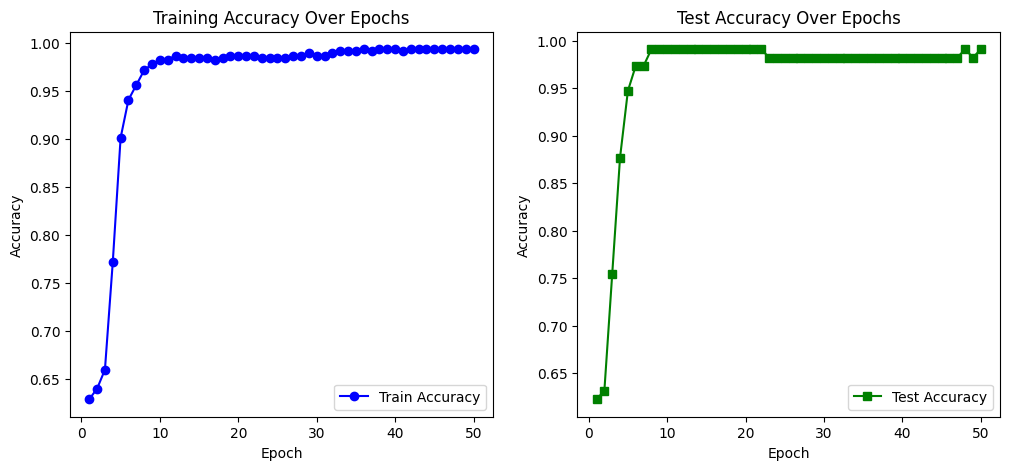

In [8]:
# don't change this cell
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, NUM_EPOCHS+1), train_accuracy_list, marker='o', linestyle='-', color='b', label="Train Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy Over Epochs")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, NUM_EPOCHS+1), test_accuracy_list, marker='s', linestyle='-', color='g', label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Test Accuracy Over Epochs")
plt.legend()

plt.show()